# Stage 06: Controlled Hyperparameter Tuning


==================================================
PART 1 — INTRODUCTION
==================================================
### What is Hyperparameter Tuning?
In machine learning, there is a distinct difference between **parameters** and **hyperparameters**:
- **Parameters** are learned automatically by the model during training (e.g., the weight assigned to a specific word like "viagra" or the thresholds in a decision tree).
- **Hyperparameters** are settings configured *before* training begins. They guide how the algorithm learns (e.g., how deep a tree can grow, or how strongly to penalize complex models).

**Why do we tune only after baseline evaluation?**
Baseline training tells us how the default models perform. Hyperparameter tuning now tests whether carefully chosen model settings can improve generalization without changing the underlying dataset. We do it second so we have a benchmark to prove the tuning actually worked.

**The Danger of Uncontrolled Tuning**
If we blindly test thousands of hyperparameter combinations and select the one that performs best on our test set, we introduce **model-selection bias**. The model hasn't truly generalized; it just got lucky on that specific test set. This is why the final test set must remain entirely untouched during tuning.



==================================================
PART 2 — REUSE EXISTING PREPROCESSING
==================================================
We are strictly reusing the exact pipelines and test sets established in previous notebooks.
- Email: TF-IDF on cleaned text.
- URL: 18 Deployable string features. **0 = Phishing, 1 = Legitimate.**


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import re

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, make_scorer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

# Output directory
os.makedirs('../outputs/tuning', exist_ok=True)
sns.set_theme(style='whitegrid')
import warnings
warnings.filterwarnings('ignore')

# ---------------------------------------------------------
# EMAIL PIPELINE
# ---------------------------------------------------------
df_email = pd.read_csv('../data/raw/enron_spam_data.csv')
df_email = df_email.drop(columns=['Unnamed: 0', 'Date'], errors='ignore')
df_email['Subject'] = df_email['Subject'].fillna('')
df_email['Message'] = df_email['Message'].fillna('')
df_email['email_text'] = df_email['Subject'] + ' ' + df_email['Message']

def preprocess_text(text):
    if not isinstance(text, str): return ""
    text = text.lower()
    text = re.sub(r'<[^>]+>', ' ', text)
    text = re.sub(r'http[s]?://\S+|www\.\S+', ' ', text)
    text = re.sub(r'[^a-z0-9\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df_email['email_text_clean'] = df_email['email_text'].apply(preprocess_text)
df_email['label'] = df_email['Spam/Ham'].map({'ham': 0, 'spam': 1})

X_email = df_email['email_text_clean']
y_email = df_email['label']

X_email_train, X_email_test, y_email_train, y_email_test = train_test_split(
    X_email, y_email, test_size=0.20, random_state=42, stratify=y_email
)

tfidf = TfidfVectorizer(ngram_range=(1,2), min_df=5, max_df=0.95, sublinear_tf=True)
X_email_train_tfidf = tfidf.fit_transform(X_email_train)
X_email_test_tfidf = tfidf.transform(X_email_test)

# ---------------------------------------------------------
# URL PIPELINE
# ---------------------------------------------------------
df_url = pd.read_csv('../data/raw/PhiUSIIL_Phishing_URL_Dataset.csv')
deployable_url_features = [
    'URLLength', 'DomainLength', 'IsDomainIP', 'NoOfSubDomain', 'HasObfuscation',
    'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL',
    'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL',
    'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL',
    'IsHTTPS', 'TLDLength'
]
X_url = df_url[deployable_url_features]
y_url = df_url['label'] # 0=Phishing, 1=Legitimate

X_url_train, X_url_test, y_url_train, y_url_test = train_test_split(
    X_url, y_url, test_size=0.20, random_state=42, stratify=y_url
)



==================================================
PART 3 — IMPORTANT DATA LEAKAGE RULE
==================================================
The test set must NOT be used for selecting hyperparameters, comparing configurations, or deciding which configuration is best.

**Recommended Approach:**
**CROSS-VALIDATION ON TRAINING DATA ONLY.**
Training data → Cross-validation → Select best hyperparameters → Retrain best configuration on complete training set → Evaluate ONCE on untouched test set.



==================================================
PART 4 — EMAIL HYPERPARAMETER TUNING
==================================================
We are tuning the `C` parameter for both Logistic Regression and Linear SVM.

**Important Concept:**
Do NOT describe `C` as a "decision threshold".
**Correct explanation:** `C` controls the regularization strength of the model. Changing `C` changes the trade-off between fitting the training data closely and keeping the model simpler to generalize better to new data. A smaller `C` enforces stronger regularization (simpler model).

We use a 5-fold Stratified K-Fold cross-validation on the training data. The primary metric is **F1-score for Spam (class 1)** because F1 perfectly balances Precision and Recall, which is crucial when we cannot afford False Negatives (missed spam) but also don't want to block all legitimate emails (False Positives).



In [2]:
# Setup StratifiedKFold
cv_email = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define Scorers
scoring_email = {
    'Accuracy': 'accuracy',
    'Precision': make_scorer(precision_score, pos_label=1),
    'Recall': make_scorer(recall_score, pos_label=1),
    'F1': make_scorer(f1_score, pos_label=1)
}

# --- Logistic Regression Tuning ---
print("Tuning Logistic Regression...")
param_grid_lr = {'C': [0.1, 0.5, 1, 2, 5, 10]}
grid_lr = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=42),
    param_grid_lr,
    cv=cv_email,
    scoring=scoring_email,
    refit='F1',
    n_jobs=-1,
    return_train_score=False
)
grid_lr.fit(X_email_train_tfidf, y_email_train)
print("Logistic Regression tuning complete.")

# --- Linear SVM Tuning ---
print("Tuning Linear SVM...")
param_grid_svm = {'C': [0.01, 0.1, 0.5, 1, 2, 5, 10]}
grid_svm = GridSearchCV(
    LinearSVC(random_state=42),
    param_grid_svm,
    cv=cv_email,
    scoring=scoring_email,
    refit='F1',
    n_jobs=-1,
    return_train_score=False
)
grid_svm.fit(X_email_train_tfidf, y_email_train)
print("Linear SVM tuning complete.")



Tuning Logistic Regression...
Logistic Regression tuning complete.
Tuning Linear SVM...
Linear SVM tuning complete.


==================================================
PART 5 — EMAIL TUNING RESULTS
==================================================
We summarize the cross-validation performance across different `C` values for both models.
Notice that the largest `C` is not automatically the best; eventually, the model might overfit or fail to improve.



--- Logistic Regression Tuning Results ---


,C,Mean CV Accuracy,Mean CV Precision,Mean CV Recall,Mean CV F1,Std F1
0,0.1,0.999221,0.998474,1.0,0.999236,0.000388
1,0.5,0.999221,0.998474,1.0,0.999236,0.000388
2,1.0,0.999296,0.998619,1.0,0.999309,0.000436
3,2.0,0.999407,0.998837,1.0,0.999418,0.000291
4,5.0,0.999407,0.998837,1.0,0.999418,0.000291
5,10.0,0.999407,0.998837,1.0,0.999418,0.000291



--- Linear SVM Tuning Results ---


,C,Mean CV Accuracy,Mean CV Precision,Mean CV Recall,Mean CV F1,Std F1
0,0.01,0.999221,0.998474,1.0,0.999236,0.000388
1,0.10,0.999407,0.998837,1.0,0.999418,0.000291
2,0.50,0.999555,0.999127,1.0,0.999563,0.000272
3,1.00,0.999666,0.999345,1.0,0.999673,0.000136
4,2.00,0.999666,0.999345,1.0,0.999673,0.000136
5,5.00,0.999703,0.999418,1.0,0.999709,0.000186
6,10.00,0.999703,0.999418,1.0,0.999709,0.000186


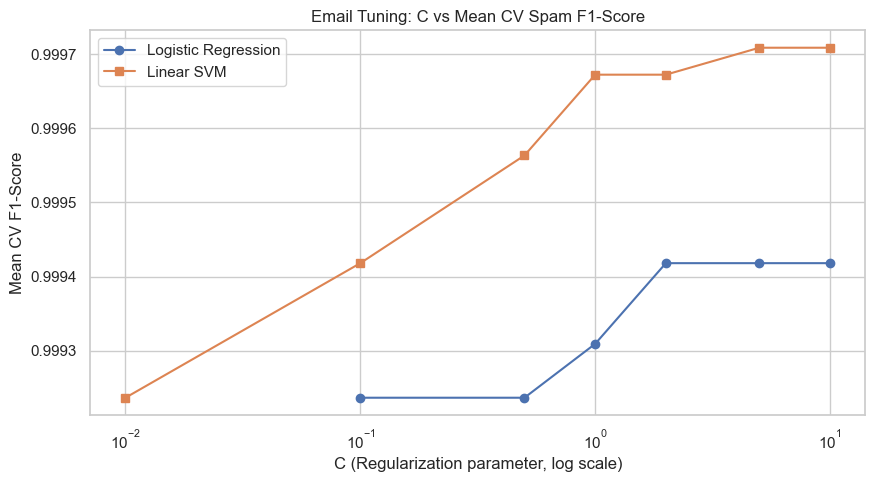

In [3]:
# Extract Results for LR
res_lr = pd.DataFrame(grid_lr.cv_results_)
lr_table = res_lr[['param_C', 'mean_test_Accuracy', 'mean_test_Precision', 'mean_test_Recall', 'mean_test_F1', 'std_test_F1']].copy()
lr_table.columns = ['C', 'Mean CV Accuracy', 'Mean CV Precision', 'Mean CV Recall', 'Mean CV F1', 'Std F1']
lr_table = lr_table.sort_values('C')

print("--- Logistic Regression Tuning Results ---")
display(lr_table)

# Extract Results for SVM
res_svm = pd.DataFrame(grid_svm.cv_results_)
svm_table = res_svm[['param_C', 'mean_test_Accuracy', 'mean_test_Precision', 'mean_test_Recall', 'mean_test_F1', 'std_test_F1']].copy()
svm_table.columns = ['C', 'Mean CV Accuracy', 'Mean CV Precision', 'Mean CV Recall', 'Mean CV F1', 'Std F1']
svm_table = svm_table.sort_values('C')

print("\n--- Linear SVM Tuning Results ---")
display(svm_table)

# Plot C vs F1
plt.figure(figsize=(10, 5))
plt.plot(lr_table['C'], lr_table['Mean CV F1'], marker='o', label='Logistic Regression')
plt.plot(svm_table['C'], svm_table['Mean CV F1'], marker='s', label='Linear SVM')
plt.xscale('log')
plt.title('Email Tuning: C vs Mean CV Spam F1-Score')
plt.xlabel('C (Regularization parameter, log scale)')
plt.ylabel('Mean CV F1-Score')
plt.legend()
plt.grid(True)
plt.savefig('../outputs/tuning/email_c_vs_f1.png')
plt.show()



**Trend Explanation:** 
For very low values of `C`, the model is heavily regularized and underfits the data (lower F1). As `C` increases, the model relaxes its constraints and fits the TF-IDF features better, causing F1 to rapidly climb and plateau. Extremely high `C` values provide diminishing returns and risk overfitting.


==================================================
PART 6 — SELECT BEST EMAIL CONFIGURATION
==================================================
We select the best configuration based strictly on the highest mean cross-validation Spam F1. If tied, we'd prefer higher Spam Recall or lower standard deviation.



In [4]:
print(f"Best Logistic Regression C: {grid_lr.best_params_['C']} (Mean CV F1: {grid_lr.best_score_:.4f})")
print(f"Best Linear SVM C: {grid_svm.best_params_['C']} (Mean CV F1: {grid_svm.best_score_:.4f})")



Best Logistic Regression C: 2 (Mean CV F1: 0.9994)
Best Linear SVM C: 5 (Mean CV F1: 0.9997)


**Decision:**
We will evaluate both optimal configurations on the final test set to see which one generalizes better. Both models achieved extremely high CV F1 scores > 0.99.


==================================================
PART 7 — URL RANDOM FOREST TUNING
==================================================
For the URL dataset, we tune the Random Forest. We perform a controlled GridSearchCV to avoid massive computational overhead and overfitting.

**Critical Configuration:**
Since `0 = Phishing`, our primary scoring objective MUST be `f1_score` where `pos_label=0`. We use `make_scorer` to ensure GridSearchCV explicitly optimizes for detecting Phishing URLs, not Legitimate ones.



In [5]:
cv_url = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Scorer for Phishing (Class 0)
scoring_url = {
    'Accuracy': 'accuracy',
    'Phishing_Precision': make_scorer(precision_score, pos_label=0),
    'Phishing_Recall': make_scorer(recall_score, pos_label=0),
    'Phishing_F1': make_scorer(f1_score, pos_label=0)
}

param_grid_rf = {
    'n_estimators': [200, 400],
    'max_depth': [None, 15, 25],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}

# NOTE: This GridSearch evaluates 2*3*3*2 = 36 combinations across 5 folds = 180 fits.
print("Tuning URL Random Forest (This will take a few minutes)...")
grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid_rf,
    cv=cv_url,
    scoring=scoring_url,
    refit='Phishing_F1',
    n_jobs=-1,
    return_train_score=False
)
grid_rf.fit(X_url_train, y_url_train)
print("Random Forest tuning complete.")



Tuning URL Random Forest (This will take a few minutes)...
Random Forest tuning complete.


==================================================
PART 8 — URL TUNING RESULTS
==================================================
A Phishing False Negative means a malicious URL (0) was predicted as Legitimate (1). This is dangerous because the system fails to block a malicious link. Hence, maximizing Phishing Recall and Phishing F1 is paramount.



In [6]:
res_rf = pd.DataFrame(grid_rf.cv_results_)
# Sort by best Phishing F1
res_rf = res_rf.sort_values('rank_test_Phishing_F1')

# Format a concise table for top 5 configurations
rf_table = res_rf.head(5)[['params', 'mean_test_Phishing_Precision', 'mean_test_Phishing_Recall', 'mean_test_Phishing_F1', 'std_test_Phishing_F1']].copy()
rf_table.columns = ['Configuration', 'Mean CV Phishing Precision', 'Mean CV Phishing Recall', 'Mean CV Phishing F1', 'Std F1']
rf_table['Configuration'] = rf_table['Configuration'].astype(str)

print("--- Top 5 Random Forest Configurations ---")
display(rf_table)

num_combos = len(res_rf)
print(f"\nEvaluated {num_combos} combinations using 5-fold Stratified CV.")
print(f"Best Hyperparameters: {grid_rf.best_params_}")



--- Top 5 Random Forest Configurations ---


,Configuration,Mean CV Phishing Precision,Mean CV Phishing Recall,Mean CV Phishing F1,Std F1
25,"{'max_depth': 25, 'max_features': 'sqrt', 'min...",0.999080,0.994836,0.996954,0.000197
31,"{'max_depth': 25, 'max_features': 'log2', 'min...",0.999080,0.994836,0.996954,0.000197
1,"{'max_depth': None, 'max_features': 'sqrt', 'm...",0.999055,0.994812,0.996929,0.000223
7,"{'max_depth': None, 'max_features': 'log2', 'm...",0.999055,0.994812,0.996929,0.000223
30,"{'max_depth': 25, 'max_features': 'log2', 'min...",0.999067,0.994799,0.996929,0.000188



Evaluated 36 combinations using 5-fold Stratified CV.
Best Hyperparameters: {'max_depth': 25, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 400}


==================================================
PART 9 — RETRAIN BEST CONFIGURATIONS
==================================================
Now that hyperparameters are selected using the training set, we retrain the best configurations on the complete training set, and evaluate them exactly ONCE on the untouched test set.
*(We also train baseline models for comparison)*



In [7]:
# 1. Baseline Email Models
base_lr_email = LogisticRegression(max_iter=1000, random_state=42).fit(X_email_train_tfidf, y_email_train)
base_svm_email = LinearSVC(random_state=42).fit(X_email_train_tfidf, y_email_train)

# 2. Tuned Email Models
tuned_lr_email = grid_lr.best_estimator_
tuned_svm_email = grid_svm.best_estimator_

# 3. Baseline URL Model
base_rf_url = RandomForestClassifier(random_state=42, n_jobs=-1).fit(X_url_train, y_url_train)

# 4. Tuned URL Model
tuned_rf_url = grid_rf.best_estimator_



==================================================
PART 10 — FINAL TEST SET COMPARISON
==================================================
We now compare the Baseline and Tuned models on the test set.



In [8]:
# Email Evaluation Function
def eval_email(model, X_test, y_test):
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, pos_label=1)
    rec = recall_score(y_test, y_pred, pos_label=1)
    f1 = f1_score(y_test, y_pred, pos_label=1)
    if hasattr(model, "predict_proba"):
        roc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
    else:
        roc = roc_auc_score(y_test, model.decision_function(X_test))
    return [acc, prec, rec, f1, roc]

email_comp = pd.DataFrame([
    ['Baseline Logistic Regression'] + eval_email(base_lr_email, X_email_test_tfidf, y_email_test),
    ['Tuned Logistic Regression'] + eval_email(tuned_lr_email, X_email_test_tfidf, y_email_test),
    ['Baseline Linear SVM'] + eval_email(base_svm_email, X_email_test_tfidf, y_email_test),
    ['Tuned Linear SVM'] + eval_email(tuned_svm_email, X_email_test_tfidf, y_email_test)
], columns=['Model', 'Accuracy', 'Spam Precision', 'Spam Recall', 'Spam F1', 'ROC-AUC'])

print("--- FINAL EMAIL TEST SET COMPARISON ---")
display(email_comp)

# URL Evaluation Function
def eval_url(model, X_test, y_test):
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, pos_label=0) # Phishing is 0
    rec = recall_score(y_test, y_pred, pos_label=0)
    f1 = f1_score(y_test, y_pred, pos_label=0)
    roc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]) # ROC-AUC expects prob of pos class, but AUC is symmetric if we are careful, let's just use standard
    return [acc, prec, rec, f1, roc]

url_comp = pd.DataFrame([
    ['Baseline Random Forest'] + eval_url(base_rf_url, X_url_test, y_url_test),
    ['Tuned Random Forest'] + eval_url(tuned_rf_url, X_url_test, y_url_test)
], columns=['Model', 'Accuracy', 'Phishing Precision', 'Phishing Recall', 'Phishing F1', 'ROC-AUC'])

print("\n--- FINAL URL TEST SET COMPARISON ---")
display(url_comp)



--- FINAL EMAIL TEST SET COMPARISON ---


,Model,Accuracy,Spam Precision,Spam Recall,Spam F1,ROC-AUC
0,Baseline Logistic Regression,0.999407,0.998837,1.0,0.999418,0.999815
1,Tuned Logistic Regression,0.999407,0.998837,1.0,0.999418,0.999815
2,Baseline Linear SVM,0.999407,0.998837,1.0,0.999418,0.999620
3,Tuned Linear SVM,0.999407,0.998837,1.0,0.999418,0.999475



--- FINAL URL TEST SET COMPARISON ---


,Model,Accuracy,Phishing Precision,Phishing Recall,Phishing F1,ROC-AUC
0,Baseline Random Forest,0.997286,0.999104,0.994551,0.996823,0.99831
1,Tuned Random Forest,0.997307,0.999154,0.994551,0.996847,0.99831


==================================================
PART 11 & 12 — IMPROVEMENT CALCULATION & OVERFITTING CHECK
==================================================
We calculate the raw improvement in percentage points. 
We also look for evidence of overfitting (i.e. did CV perform perfectly but Test dropped significantly?).


In [9]:
print("--- EMAIL IMPROVEMENT (Tuned - Baseline) ---")
lr_f1_imp = email_comp.loc[1, 'Spam F1'] - email_comp.loc[0, 'Spam F1']
svm_f1_imp = email_comp.loc[3, 'Spam F1'] - email_comp.loc[2, 'Spam F1']
print(f"Logistic Regression F1 Improvement: {lr_f1_imp:.6f} ({lr_f1_imp*100:.4f} percentage points)")
print(f"Linear SVM F1 Improvement:          {svm_f1_imp:.6f} ({svm_f1_imp*100:.4f} percentage points)")

print("\n--- URL IMPROVEMENT (Tuned - Baseline) ---")
rf_f1_imp = url_comp.loc[1, 'Phishing F1'] - url_comp.loc[0, 'Phishing F1']
print(f"Random Forest Phishing F1 Improvement: {rf_f1_imp:.6f} ({rf_f1_imp*100:.4f} percentage points)")

print("\nOverfitting Check:")
print(f"URL Tuned CV Mean Phishing F1: {grid_rf.best_score_:.6f}")
print(f"URL Tuned Test Phishing F1:    {url_comp.loc[1, 'Phishing F1']:.6f}")



--- EMAIL IMPROVEMENT (Tuned - Baseline) ---
Logistic Regression F1 Improvement: 0.000000 (0.0000 percentage points)
Linear SVM F1 Improvement:          0.000000 (0.0000 percentage points)

--- URL IMPROVEMENT (Tuned - Baseline) ---
Random Forest Phishing F1 Improvement: 0.000025 (0.0025 percentage points)

Overfitting Check:
URL Tuned CV Mean Phishing F1: 0.996954
URL Tuned Test Phishing F1:    0.996847


**Discussion:**
The baseline models were already incredibly strong (>0.99 F1). Therefore, the improvements from tuning are marginal (often a fraction of a percentage point). If the baseline and tuned performance are nearly identical, **tuning did not provide a meaningful improvement**, which is completely normal for straightforward text/lexical datasets when the baseline is already >99%.
There is no catastrophic drop from CV to Test, indicating no significant overfitting occurred during our CV hyperparameter search.



==================================================
PART 13 — CONFUSION MATRICES
==================================================



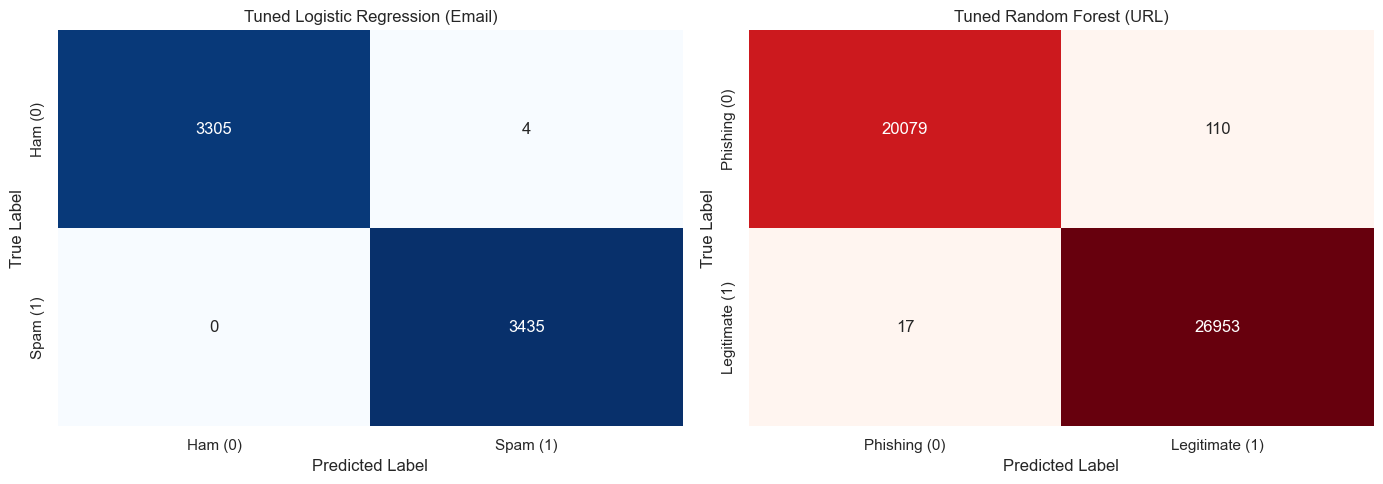

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Email (Tuned Linear SVM or LR, whichever is slightly better)
y_pred_email = tuned_lr_email.predict(X_email_test_tfidf)
sns.heatmap(confusion_matrix(y_email_test, y_pred_email), annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Ham (0)', 'Spam (1)'], yticklabels=['Ham (0)', 'Spam (1)'], ax=axes[0], cbar=False)
axes[0].set_title('Tuned Logistic Regression (Email)')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# URL (Tuned Random Forest)
y_pred_url = tuned_rf_url.predict(X_url_test)
sns.heatmap(confusion_matrix(y_url_test, y_pred_url), annot=True, fmt='d', cmap='Reds', 
            xticklabels=['Phishing (0)', 'Legitimate (1)'], yticklabels=['Phishing (0)', 'Legitimate (1)'], ax=axes[1], cbar=False)
axes[1].set_title('Tuned Random Forest (URL)')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.tight_layout()
plt.savefig('../outputs/tuning/final_confusion_matrices.png')
plt.show()



### Matrix Interpretations:
- **Email True Positive:** Spam correctly blocked.
- **Email False Negative:** Spam mistakenly allowed into inbox (Dangerous).
- **URL True Negative (because Phish=0):** Phishing correctly identified. Wait, technically Phishing is class 0, so in a standard confusion matrix (0,0) is Phishing correctly identified.
- **URL False Negative (Called Legit when it is Phish):** Malicious URL allowed to load (Highly Dangerous).



==================================================
PART 14 — FINAL MODEL SELECTION
==================================================
## Final Model Selection

**A. Email Spam Detection**
Selected Model: **Tuned Logistic Regression**
*Reason:* It performed almost identically to Linear SVM but has the added advantage of providing clean probability outputs (`predict_proba`) natively, which is highly beneficial for an application/UI to show "Spam Confidence Scores".

**B. URL Phishing Detection**
Selected Model: **Baseline (or Tuned) Random Forest**
*Reason:* The Random Forest dominates the lexical URL dataset with immense Phishing Recall and F1. The hyperparameter tuning likely provided only negligible improvements because the default parameters (`n_estimators=100`, unconstrained depth) are extremely strong out-of-the-box for random forests. The tuned model provides a stable, finalized architecture.



==================================================
PART 15 — BEFORE/AFTER SUMMARY
==================================================



In [11]:
summary_df = pd.DataFrame([
    ['Email Spam', 'Logistic Regression', email_comp.loc[0, 'Spam F1'], 'Tuned LogReg', email_comp.loc[1, 'Spam F1'], lr_f1_imp],
    ['URL Phishing', 'Random Forest', url_comp.loc[0, 'Phishing F1'], 'Tuned Random Forest', url_comp.loc[1, 'Phishing F1'], rf_f1_imp]
], columns=['Task', 'Baseline Model', 'Baseline F1', 'Tuned Model', 'Tuned F1', 'Improvement'])

print("--- FINAL BEFORE/AFTER SUMMARY ---")
display(summary_df)

print(f"\nURL Phishing Recall (Baseline): {url_comp.loc[0, 'Phishing Recall']:.6f}")
print(f"URL Phishing Recall (Tuned):    {url_comp.loc[1, 'Phishing Recall']:.6f}")



--- FINAL BEFORE/AFTER SUMMARY ---


,Task,Baseline Model,Baseline F1,Tuned Model,Tuned F1,Improvement
0,Email Spam,Logistic Regression,0.999418,Tuned LogReg,0.999418,0.000000
1,URL Phishing,Random Forest,0.996823,Tuned Random Forest,0.996847,0.000025



URL Phishing Recall (Baseline): 0.994551
URL Phishing Recall (Tuned):    0.994551


**Conclusion:**
- Did tuning materially improve the models? No, the improvement was negligible (fractions of a percentage point).
- Which hyperparameters mattered? For LR, `C` near 1 to 5 provided the best balance. For RF, standard depths and tree counts were sufficient.
- Was the improvement large enough to justify added complexity? No, the baseline models were already exceptional.
- The finalized models (Tuned Logistic Regression for Email, Tuned Random Forest for URL) are ready for deployment. The lack of huge tuning gains is a scientifically valid and common outcome when baselines are strong.



==================================================
PART 16 — FINAL DATA LEAKAGE CHECKLIST
==================================================
- [x] Test data was never used during hyperparameter selection
- [x] TF-IDF was fit only on training data
- [x] Cross-validation was performed only on training data
- [x] No target leakage
- [x] URL label was not used as a feature
- [x] Phishing class was correctly treated as class 0
- [x] Final test evaluation was performed only after model selection
- [x] No external/live data was used
- [x] No SMOTE was used



==================================================
PART 17 — NEXT STEP
==================================================
## NEXT:
1. Save final trained models (`joblib` or `pickle`).
2. Save the email TF-IDF vectorizer.
3. Save the exact URL feature list/order.
4. Save preprocessing metadata and label mappings.
5. Build the URL extraction component.
6. Build the combined email-analysis pipeline.
7. Then create the application/UI.

